# Faces to numbers to predictions
Classify two people with 12 hand-made face measurements + logistic regression. 


In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path

%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "font.size": 11})

## 1. Read the folders
One folder per person; the folder name is the label.


In [ ]:
DATASET_ROOT = Path("dataset")
PHOTO_ENDINGS = {".jpg", ".jpeg", ".png"}


def find_images(root):
    """Walk each class folder, return image paths and a label map."""
    root = Path(root)
    people = sorted(d.name for d in root.iterdir() if d.is_dir())
    if len(people) < 2:
        raise ValueError(f"need at least 2 class folders, found: {people}")
    label_of = {name: i for i, name in enumerate(people)}  
    paths = []
    for name in people:
        found = sorted(p for p in (root / name).rglob("*")
                       if p.suffix.lower() in PHOTO_ENDINGS)
        print(f"{name}: {len(found)} images")
        paths.extend(found)
    print("label map:", label_of)
    return paths, people, label_of


paths, people, label_of = find_images(DATASET_ROOT)
name_of = {i: name for name, i in label_of.items()}

person_a: 40 images
person_b: 40 images
label map: {'person_a': 0, 'person_b': 1}


In [ ]:
CASCADE_DIR = Path("models/haarcascades")


def load_cascade(filename):
    local = CASCADE_DIR / filename
    if local.exists():
        return cv2.CascadeClassifier(str(local))
    return cv2.CascadeClassifier(cv2.data.haarcascades + filename)


face_detector = load_cascade("haarcascade_frontalface_default.xml")
eye_detector = load_cascade("haarcascade_eye.xml")


def find_face(photo):
    """Face box (x, y, w, h) or None. Haar first, big-blob fallback."""
    gray = cv2.cvtColor(photo, cv2.COLOR_BGR2GRAY)
    hits = face_detector.detectMultiScale(gray, 1.1, 5, minSize=(60, 60))
    if len(hits):
        return tuple(max(hits, key=lambda b: b[2] * b[3]))
    mask = ((photo < 250).any(axis=2)).astype("uint8") * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((9, 9), "uint8"))
    n, _, stats, _ = cv2.connectedComponentsWithStats(mask)
    big = [stats[i] for i in range(1, n) if stats[i][4] > 3000]
    if not big:
        return None
    x, y, w, h, _ = max(big, key=lambda s: s[4])
    return (x, y, w, h)

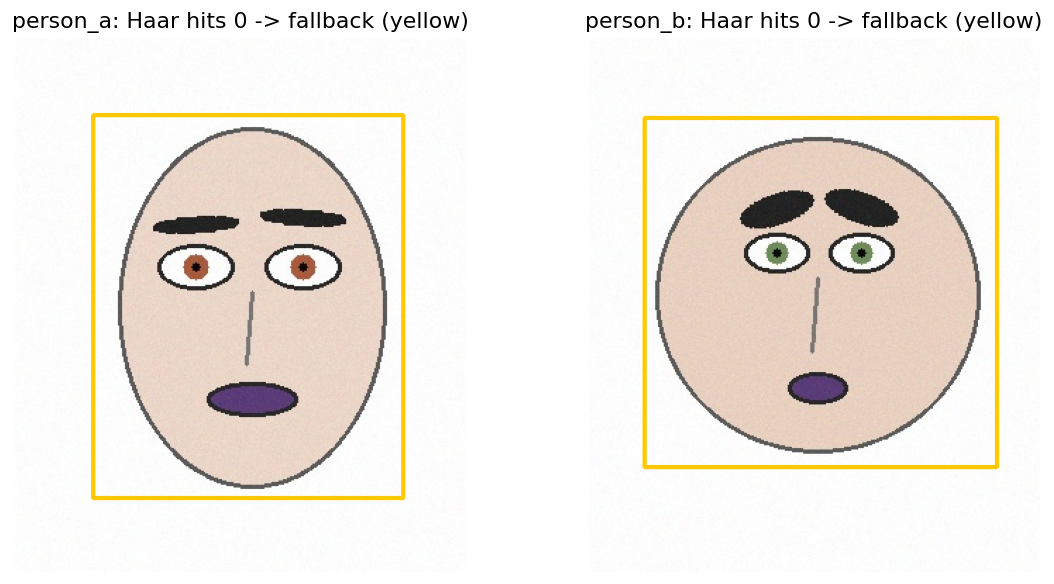

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, person in zip(axes, people):
    path = sorted((DATASET_ROOT / person).glob("*"))[0]
    photo = cv2.imread(str(path))
    gray = cv2.cvtColor(photo, cv2.COLOR_BGR2GRAY)
    view = cv2.cvtColor(photo, cv2.COLOR_BGR2RGB)
    # raw Haar output (no fallback here): green faces, blue eyes
    faces = face_detector.detectMultiScale(gray, 1.1, 5, minSize=(60, 60))
    for (x, y, w, h) in faces:
        cv2.rectangle(view, (x, y), (x + w, y + h), (0, 200, 0), 2)
        for (ex, ey, ew, eh) in eye_detector.detectMultiScale(
                gray[y:y + h, x:x + w], 1.1, 4, minSize=(12, 12)):
            cv2.rectangle(view, (x + ex, y + ey),
                          (x + ex + ew, y + ey + eh), (0, 100, 255), 2)
    if not len(faces):  # Haar trained on real photos, not drawings
        x, y, w, h = find_face(photo)  # contour fallback, yellow
        cv2.rectangle(view, (x, y), (x + w, y + h), (255, 200, 0), 2)
    ax.imshow(view)
    ax.set_title(f"{person}: Haar hits {len(faces)} -> "
                   + ("Haar" if len(faces) else "fallback (yellow)"))
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Measure each face
Haar cascades find the face, plain OpenCV finds eyes, mouth, brows, shape, iris. Anything missing -> photo is skipped, never guessed.


In [ ]:
def find_eyes(face_gray, face_color):
    """Return (left_x, left_w, right_x, right_w, mid_y, top_y, iris_hsv)."""
    h, w = face_gray.shape
    upper = face_gray[:int(h * 0.55), :]
    uh = upper.shape[0]

    def pupil_points():
        blur = cv2.GaussianBlur(upper, (5, 5), 0)
        _, dark = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
        dark = cv2.morphologyEx(dark, cv2.MORPH_OPEN, np.ones((3, 3), "uint8"))
        contours, _ = cv2.findContours(dark, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        pts = []
        for c in contours:
            area = cv2.contourArea(c)
            x, y, bw, bh = cv2.boundingRect(c)
            if 40 < area < w * uh * 0.08 and bh < uh * 0.5 and bw < w * 0.35:
                m = cv2.moments(c)
                if m["m00"]:
                    pts.append((m["m10"] / m["m00"], m["m01"] / m["m00"]))
        return pts

    def iris_average(pts):
        hsv = cv2.cvtColor(face_color, cv2.COLOR_BGR2HSV)
        samples = []
        for px, py in pts:
            patch = hsv[max(0, int(py) - 4):int(py) + 5, max(0, int(px) - 4):int(px) + 5]
            if patch.size:
                samples.append([patch[:, :, 0].mean(), patch[:, :, 1].mean(),
                                patch[:, :, 2].mean()])
        return np.mean(samples, axis=0) if samples else None

    hits = eye_detector.detectMultiScale(upper, 1.1, 4, minSize=(12, 12))
    if len(hits) >= 2:
        (lx, ly, lw, lh), (rx, ry, rw, rh) = sorted(hits, key=lambda b: b[0])[:2]
        iris = iris_average(pupil_points())
        if iris is None:
            return None
        return (lx + lw / 2, lw, rx + rw / 2, rw,
                (ly + lh / 2 + ry + rh / 2) / 2, min(ly, ry), iris)

    # no Haar eyes: eye-white blobs. Otsu fails here (one big skin peak),
    # so use a fixed near-white cut, then drop white touching the border.
    _, bright = cv2.threshold(upper, 245, 255, cv2.THRESH_BINARY)
    flood = bright.copy()
    cv2.floodFill(flood, np.zeros((uh + 2, w + 2), "uint8"), (0, 0), 128)
    whites = (((bright == 255) & (flood != 128)).astype("uint8")) * 255
    contours, _ = cv2.findContours(whites, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    candidates = []
    for c in contours:
        area = cv2.contourArea(c)
        x, y, bw, bh = cv2.boundingRect(c)
        if not (200 < area < w * uh * 0.15):
            continue
        if not (w * 0.05 < bw < w * 0.4 and bh >= 5 and bw / bh >= 1.2):
            continue
        m = cv2.moments(c)
        if m["m00"]:
            candidates.append((m["m10"] / m["m00"], bw, m["m01"] / m["m00"], bh, area))
    left = [c for c in candidates if c[0] < w / 2]
    right = [c for c in candidates if c[0] >= w / 2]
    if not (left and right):
        return None
    left = max(left, key=lambda c: c[4])
    right = max(right, key=lambda c: c[4])
    iris = iris_average(pupil_points())
    if iris is None:
        return None
    mid_y = (left[2] + right[2]) / 2
    return (left[0], left[1], right[0], right[1], mid_y,
            mid_y - (left[3] + right[3]) / 2, iris)

In [ ]:
def find_mouth(face_gray):
    """Dark horizontal blob in the lower-center face. Returns (cx, cy, width)."""
    h, w = face_gray.shape
    x0, x1 = int(w * 0.15), int(w * 0.85)
    y0, y1 = int(h * 0.55), int(h * 0.95)
    lower = cv2.GaussianBlur(face_gray[y0:y1, x0:x1], (5, 5), 0)
    otsu, _ = cv2.threshold(lower, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    # cap: Otsu sometimes splits skin-vs-background instead of mouth-vs-skin
    _, dark = cv2.threshold(lower, min(otsu, 130), 255, cv2.THRESH_BINARY_INV)
    dark = cv2.morphologyEx(dark, cv2.MORPH_CLOSE, np.ones((5, 5), "uint8"))
    contours, _ = cv2.findContours(dark, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    best = None
    for c in contours:
        area = cv2.contourArea(c)
        x, y, bw, bh = cv2.boundingRect(c)
        if not (w * 0.08 < bw < w * 0.7 and 3 < bh < lower.shape[0] * 0.4):
            continue
        if bw / max(bh, 1) < 1.5:  # mouths are wider than tall
            continue
        m = cv2.moments(c)
        if m["m00"] and (best is None or area > best[0]):
            best = (area, m["m10"] / m["m00"], y + bh // 2, bw)
    if best is None:
        return None
    return best[1] + x0, best[2] + y0, best[3]

In [ ]:
def find_brows(face_gray, eye_mid_y):
    """Dark horizontal blobs above the eyes. Returns (gap, thickness, angle)."""
    h, w = face_gray.shape
    top = max(0, int(eye_mid_y) - int(h * 0.22))
    bottom = max(top + 4, int(eye_mid_y) - int(h * 0.05))
    band = face_gray[top:bottom, int(w * 0.25):int(w * 0.75)]  # skip edge outline
    bh, bw = band.shape
    otsu, _ = cv2.threshold(band, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    _, dark = cv2.threshold(band, min(otsu, 130), 255, cv2.THRESH_BINARY_INV)
    dark = cv2.morphologyEx(dark, cv2.MORPH_OPEN, np.ones((3, 3), "uint8"))
    n, _, stats, centers = cv2.connectedComponentsWithStats(dark)
    blobs = []
    for i in range(1, n):
        x, y, bw_b, bh_b, area = stats[i]
        if area >= 50 and bw_b >= 0.12 * bw and bh_b <= 0.65 * bh:
            blobs.append((area, x, y, bw_b, bh_b, centers[i]))
    if not blobs:
        return None
    blobs = sorted(blobs, key=lambda b: -b[0])[:2]
    thickness = float(np.mean([b[4] for b in blobs]))
    gap = float(eye_mid_y - np.mean([top + b[5][1] for b in blobs]))
    angles = []
    for _, x, y, bw_b, bh_b, _ in blobs:
        ys, xs = np.where(dark[y:y + bh_b, x:x + bw_b] > 0)
        if len(xs) > 10:
            slope, _ = np.polyfit(xs, ys, 1)
            angles.append(abs(float(np.degrees(np.arctan(slope)))))
    return gap, thickness, float(np.mean(angles)) if angles else 0.0

In [ ]:
FEATURE_COLUMNS = [
    "face_aspect_ratio",
    "eye_spacing_ratio",
    "eye_size_ratio",
    "eye_to_mouth_ratio",
    "mouth_width_ratio",
    "mouth_position_ratio",
    "eyebrow_eye_distance_ratio",
    "eyebrow_thickness_ratio",
    "eyebrow_angle",
    "forehead_width_ratio",
    "jaw_width_ratio",
    "iris_color_descriptor",
]


def face_widths(face_gray):
    """Silhouette widths at forehead / middle / jaw from edge outlines.

    Canny picks up the face boundary; per row the outermost edge pixels
    are the silhouette, interior features (eyes, mouth) are narrower.
    """
    h, w = face_gray.shape
    edges = cv2.Canny(face_gray, 50, 150)

    def band_width(lo, hi):
        seg = edges[int(h * lo):int(h * hi), :]
        widths = []
        for row in seg:
            xs = np.where(row > 0)[0]
            if len(xs) >= 2:
                widths.append(xs[-1] - xs[0])
        return float(np.median(widths)) if widths else 0.0

    fw = band_width(0.10, 0.30)
    mw = band_width(0.35, 0.65)
    jw = band_width(0.70, 0.92)
    if min(fw, mw, jw) <= 0:  # edge map failed -> neutral guess
        return 0.9 * w, float(w), 0.85 * w
    return fw, mw, jw


def measure_features(photo):
    """One photo -> dict of exactly the 12 numbers. Raises if anything is missing."""
    box = find_face(photo)
    if box is None:
        raise ValueError("no face found")
    x, y, w, h = box
    face_color = photo[y:y + h, x:x + w]
    # real photos vary in size: normalize the crop so the pixel
    # thresholds below see a ~220px-wide face. Features are ratios,
    # so this changes scale, not measurements.
    scale = 220 / max(w, 1)
    face_color = cv2.resize(face_color, (220, max(1, round(h * scale))))
    face_gray = cv2.cvtColor(face_color, cv2.COLOR_BGR2GRAY)
    fh, fw = face_gray.shape
    if min(fw, fh) < 20:
        raise ValueError("face box too small")

    eyes = find_eyes(face_gray, face_color)
    if eyes is None:
        raise ValueError("eyes not found")
    left_x, left_w, right_x, right_w, mid_y, _, iris = eyes

    mouth = find_mouth(face_gray)
    if mouth is None:
        raise ValueError("mouth not found")
    mouth_x, mouth_y, mouth_w = mouth

    brows = find_brows(face_gray, mid_y)
    if brows is None:
        raise ValueError("eyebrows not found")
    gap, thick, angle = brows

    forehead, widest, jaw = face_widths(face_gray)
    widest = max(widest, 1.0)

    features = {
        "face_aspect_ratio": fh / fw,
        "eye_spacing_ratio": abs(right_x - left_x) / fw,
        "eye_size_ratio": ((left_w + right_w) / 2) / fw,
        "eye_to_mouth_ratio": (mouth_y - mid_y) / fh,
        "mouth_width_ratio": mouth_w / fw,
        "mouth_position_ratio": mouth_y / fh,
        "eyebrow_eye_distance_ratio": gap / fh,
        "eyebrow_thickness_ratio": thick / fh,
        "eyebrow_angle": float(angle),
        "forehead_width_ratio": forehead / widest,
        "jaw_width_ratio": jaw / widest,
        "iris_color_descriptor": float(iris[0] + iris[1] / 255.0),  # hue + saturation tint
    }
    if not np.all(np.isfinite(list(features.values()))):
        raise ValueError("non-finite measurement")
    return features

## 3. Build the table
12 numbers + label per photo, cached to CSV.


In [ ]:
REBUILD = False
CACHE_PATH = Path("data/processed/features.csv")


def build_table(root, cache_path, force=False):
    if cache_path.exists() and not force:
        print(f"reusing cached table ({cache_path})")
        cached = pd.read_csv(cache_path)
        if "image_id" in cached.columns and "image" not in cached.columns:
            cached = cached.rename(columns={"image_id": "image"})  # older cache layout
        return cached, pd.DataFrame()
    image_paths, _, labels = find_images(root)
    rows, failures = [], []
    for p in image_paths:
        photo = cv2.imread(str(p))
        if photo is None:
            failures.append({"image": str(p), "reason": "unreadable file"})
            continue
        try:
            feats = measure_features(photo)
        except ValueError as e:
            failures.append({"image": str(p), "reason": str(e)})
            continue
        feats["label"] = labels[p.parent.name]
        feats["image"] = str(p)
        rows.append(feats)
    if not rows:
        raise RuntimeError("no usable faces check the failure table")
    df = pd.DataFrame(rows)
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(cache_path, index=False)
    print(f"kept {len(df)}, skipped {len(failures)} -> {cache_path}")
    return df, pd.DataFrame(failures)


df, failures = build_table(DATASET_ROOT, CACHE_PATH, force=REBUILD)

reusing cached table (data\processed\features.csv)


## 4. Peek at the table
`image` is for debugging only and never enters the model.


In [ ]:
print(df.head().round(3).to_string())
print("\nshape:", df.shape, "| features:", FEATURE_COLUMNS)
print("\nclass counts:")
print(df["label"].map(name_of).value_counts().to_string())
print("\nmissing values:", int(df[FEATURE_COLUMNS].isna().sum().sum()),
      "| infinite values:", int(np.isinf(df[FEATURE_COLUMNS].to_numpy()).sum()))
if len(failures):
    print("\nskipped images:", len(failures))
    print(failures["reason"].value_counts().to_string())
else:
    print("\nno skipped images" + (" (loaded from cache; rebuild to recount)" if not REBUILD else ""))

   face_aspect_ratio  eye_spacing_ratio  eye_size_ratio  eye_to_mouth_ratio  mouth_width_ratio  mouth_position_ratio  eyebrow_eye_distance_ratio  eyebrow_thickness_ratio  eyebrow_angle  forehead_width_ratio  jaw_width_ratio  iris_color_descriptor  label                        image
0              1.236              0.345           0.223               0.346              0.295                 0.743                       0.121                    0.048          3.641                 0.771            0.777                 35.796      0  dataset\person_a\img001.jpg
1              1.327              0.357           0.307               0.330              0.300                 0.729                       0.108                    0.048          3.624                 0.676            0.764                 36.936      0  dataset\person_a\img002.jpg
2              1.373              0.375           0.298               0.352              0.309                 0.725                       0.117       

## 5. Plot a few features
Same two colors everywhere.


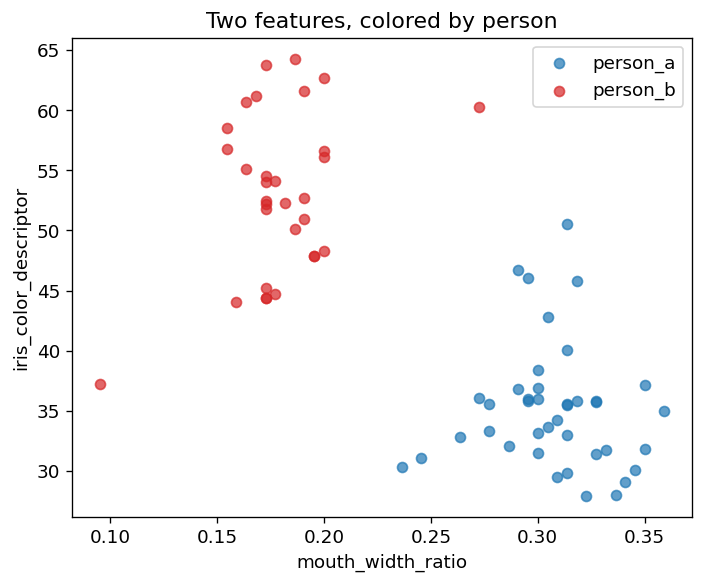

In [ ]:
PERSON_COLORS = {people[0]: "#1f77b4", people[1]: "#d62728"}
plot_df = df.copy()
plt.figure(figsize=(6, 5))
for person, color in PERSON_COLORS.items():
    sub = plot_df[plot_df["person"] == person]
    plt.scatter(sub["mouth_width_ratio"], sub["iris_color_descriptor"],
                c=color, label=person, alpha=0.7)
plt.xlabel("mouth_width_ratio")
plt.ylabel("iris_color_descriptor")
plt.legend()
plt.title("Two features, colored by person")
plt.tight_layout()
plt.show()

## 6. Split into train/test
Photos come in bursts of 8 from one session, so whole sessions go to train *or* test (no near-duplicate leaks). Small data: test scores are noisy.


In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

session_of = lambda p: (int(Path(p).stem[3:]) - 1) // 8  # img001-008 -> session 0, ...
df["session"] = df["image"].apply(session_of)

splitter = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
train_idx, test_idx = next(splitter.split(df, df["label"], df["session"]))

# the ONLY model inputs: 12 numbers. Label and metadata stay out of X.
X_train, y_train = df.loc[train_idx, FEATURE_COLUMNS], df.loc[train_idx, "label"]
X_test, y_test = df.loc[test_idx, FEATURE_COLUMNS], df.loc[test_idx, "label"]
assert X_train.shape[1] == 12 and X_test.shape[1] == 12
print(f"train: {len(X_train)} photos, test: {len(X_test)} photos")
print("test sessions:", sorted(df.loc[test_idx, 'session'].unique()))
print("train label counts:", y_train.value_counts().to_dict())
print("test label counts:", y_test.value_counts().to_dict())

train: 43 photos, test: 28 photos
test sessions: [0, 4]
train label counts: {0: 24, 1: 19}
test label counts: {0: 16, 1: 12}


## 7. Train
Standardize, then logistic regression. Scaler fits on train only.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
])
model.fit(X_train, y_train)
print("trained on", len(X_train), "photos x", X_train.shape[1], "features")

trained on 43 photos x 12 features


## 8. Evaluate
Held-out accuracy, confusion matrix, a few probabilities.


train accuracy: 1.000
test accuracy:  0.964

              precision    recall  f1-score   support

    person_a       1.00      0.94      0.97        16
    person_b       0.92      1.00      0.96        12

    accuracy                           0.96        28
   macro avg       0.96      0.97      0.96        28
weighted avg       0.97      0.96      0.96        28



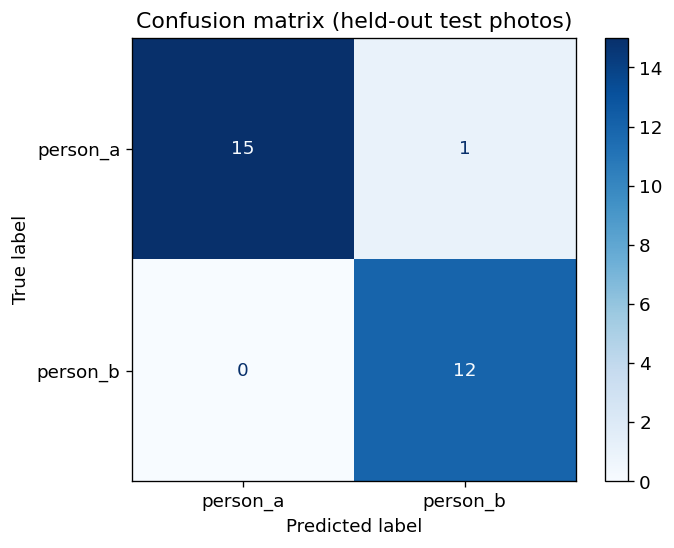

predicted probabilities for 3 test photos:
            person_a  person_b
img003.jpg     0.996     0.004
img008.jpg     0.016     0.984
img039.jpg     0.969     0.031
true labels: ['person_a', 'person_b', 'person_a']


In [ ]:
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report)

train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc = accuracy_score(y_test, model.predict(X_test))
print(f"train accuracy: {train_acc:.3f}")
print(f"test accuracy:  {test_acc:.3f}")
print("\n" + classification_report(y_test, model.predict(X_test),
      target_names=[name_of[i] for i in sorted(name_of)]))

ConfusionMatrixDisplay.from_predictions(
    y_test, model.predict(X_test),
    display_labels=[name_of[i] for i in sorted(name_of)], cmap="Blues")
plt.title("Confusion matrix (held-out test photos)")
plt.show()

sample = X_test.sample(min(3, len(X_test)), random_state=0)
probas = pd.DataFrame(model.predict_proba(sample),
                      columns=[name_of[i] for i in model.classes_],
                      index=[Path(df.loc[i, "image"]).name for i in sample.index])
print("predicted probabilities for 3 test photos:")
print(probas.round(3).to_string())
print("true labels:", [name_of[v] for v in y_test.loc[sample.index]])

## 10. New photo
Same 12 features, fitted model, no retraining.


new_person_a.jpg -> person_a (person_a: 0.990, person_b: 0.010)


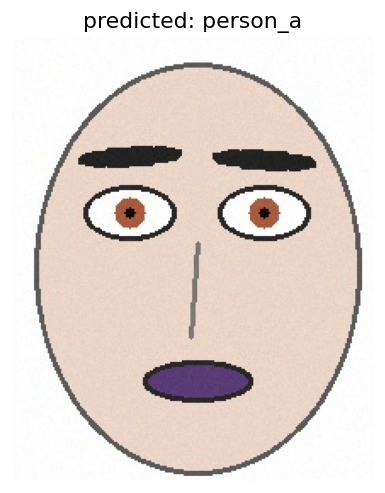

new_person_b.jpg -> person_b (person_a: 0.008, person_b: 0.992)


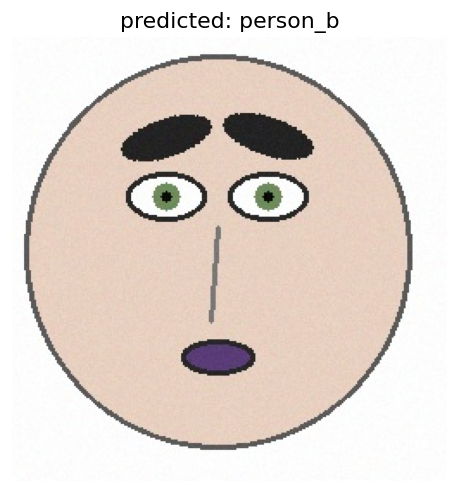

In [ ]:
def predict_image(image_path):
    photo = cv2.imread(str(image_path))
    feats = measure_features(photo)  # same extraction as training
    proba = model.predict_proba(pd.DataFrame([feats])[FEATURE_COLUMNS])[0]
    winner = name_of[model.classes_[int(np.argmax(proba))]]
    print(f"{Path(image_path).name} -> {winner} "
          f"({name_of[model.classes_[0]]}: {proba[0]:.3f}, "
          f"{name_of[model.classes_[1]]}: {proba[1]:.3f})")
    x, y, w, h = find_face(photo)
    plt.imshow(cv2.cvtColor(photo[y:y + h, x:x + w], cv2.COLOR_BGR2RGB))
    plt.title(f"predicted: {winner}")
    plt.axis("off")
    plt.show()
    return winner


for new_photo in sorted(Path("data/new_photos").glob("*")):
    predict_image(new_photo)